=============================================================================

### NOTE: Computing SHAP and permutation importance (PI) feature importances
 

=============================================================================

Best practice is to calculate SHAP values and permutation importance on
HELD-OUT test data (rows the model was not fitted on). A random forest can
nearly memorise its training data, so importances computed on training rows
mostly describe what the model memorised rather than what generalises.
(PI in particular needs held-out data to measure the loss in predictive skill.)

There are three ways to set this up, in increasing order of robustness and
compute cost:

1. Single train/test split (simplest, fastest)
   Fit the model on the training set, then compute SHAP and PI on the test
   set. Gives one importance estimate per variable, from one split, so it
   can be sensitive to which rows happen to land in the test set. Only
   test-set rows get SHAP values.

2. K-fold cross-validation (more robust, slower)
   Fit a fresh model on each training fold and compute SHAP and PI on the
   matching held-out fold. Every row gets one out-of-fold SHAP value, and
   the spread of PI/SHAP across folds shows how stable the ranking is.
   Cost: roughly K model fits, K SHAP runs and K PI runs.

3. Repeated k-fold cross-validation (most robust, slowest)
   Repeat the k-fold procedure with different random splits and average
   across repeats. Shows how sensitive the importances are to the choice of
   split, and gives each row several out-of-fold SHAP values. Cost: roughly
   (repeats x K) fits, SHAP runs and PI runs.

COMPUTE TIME: options 2 and 3 can take a long time on large datasets
(SHAP in particular). Ways to reduce it: constrain the forest
(e.g. max_depth, min_samples_leaf), explain a subsample of each test fold,
use n_jobs for PI, parallelise repeats with joblib, and start with a small
number of repeats (e.g. 3) before scaling up.


=============================================================================

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error 
from sklearn.model_selection import (KFold, cross_validate, cross_val_predict, train_test_split)
from scipy.stats import spearmanr
import shap
import time

TARGET = "prop_floodable_area_flooded" # "10cm_area"
GROUP_COL = None          # e.g. "catchment_id" / "cell_id" -- STRONGLY recommended if spatial/temporal autocorrelation
SEED = 42

from PrepDataFunctions import *
from ModelEvaluationFunctions import *

import sys, importlib
importlib.reload(sys.modules['ModelEvaluationFunctions'])
from ModelEvaluationFunctions import *

### Prepare data

In [2]:
df = prep_for_modelling(f"/scratch/hydro4/users/kv25483/FutureFlood/Data/EventDetails_v4/all_catchments_with_topo_and_temporal.pkl", 
                        remove_events_with_zero_flooding = False)
df = df[df['mean_sm_2_before_event'].notna()]

cols = ["x_coord", "y_coord"]
df["peak_cell_id"] = df.groupby(cols, sort=False).ngroup()

subset_early = create_temporal_subset(df, "before", 2020).copy()

### Things to test:
1. Remove Scotland

In [3]:
# subset_early = subset_early[subset_early['10cm_area']>0.05]

2. Remove zero flooding

In [4]:
# subset_early = subset_early[subset_early['y_coord'] < 560000]

3. Remove events only one timestep long

In [5]:
subset_early = subset_early[subset_early['length_of_active_rain']>1].copy()

### How to make this work with prop_floodable_area_flooded? 
Would need the same metric in the surroudning cells potentially?
Actually, 

In [6]:
subset_early['cluster_flood_10_area_t80_new'] = subset_early['cluster_flood_10_area_t80'] - subset_early['10cm_area']
subset_early['cluster_flood_10_area_t60_new'] = subset_early['cluster_flood_10_area_t60'] - subset_early['10cm_area']

### 1. Define variables

In [7]:
predictor_variables = ['max_precip', 'total_acc',  
                       "hc_at_peak", 'fumax_at_peak', 
#                        "x_coord", "y_coord",
#                       'se_max', 'se_min',  'sat_at_peak_new', 'sat_at_peak_old',
#                       'fu_mean_m',  'fu_min_m', 'fu_max_m', 'fu_at_peak_new', 
                        "mean_sm_2_before_event",
         'peak_position_ratio_n','d50_n','gini_n','time_based_std_n','dry_ratio_n','max_quartile_index_n',                     
                      'peak_cell_slope_avg', 'peak_cell_elev_avg','peak_cell_elev_min','peak_cell_slope_max', 
                       #'peak_cell_inside_water_prop',
                       'peak_cell_urban_prop', 
                       #'peak_cell_inside_prop', 
                      #  'prop_floodable_area_flooded',
                     'cluster_n_cells_t50', 'cluster_n_cells_t80',
                       'max_2h', 'max_3h', 'max_6h', 'max_12h', 'max_16h',
                      'cluster_flood_10_area_t60_new','cluster_flood_10_area_t80_new',
                      "random_variable"]

X = subset_early[predictor_variables]
y = subset_early[TARGET].values

In [8]:
y = pd.Series(np.asarray(y), index=X.index)

--------------------------------------------------
###  2. Identify grouped and individual predictors
--------------------------------------------------

In [9]:
variable_groups = {'Soil Saturation': ['sat_at_peak_new', 'sat_at_peak_old','fu_at_peak_new', 'mean_sm_2_before_event'],
                    'Cell slope': ['peak_cell_slope_avg', 'peak_cell_slope_max'],'Cell capacity to hold water': [
        'hc_at_peak', 'fumax_at_peak', 'peak_cell_urban_prop'],
                'Rainfall temporal profile': [
        'peak_position_ratio_n', 'd50_n', 'max_quartile_index_n']}

In [13]:
corr = subset_early[predictor_variables].corr(method="spearman")   # your existing line
THRESH = 0.65   

groups = groups_hierarchical(corr, THRESH, method="average")
multi = {k: v for k, v in groups.items() if len(v) > 1}

# Fill this in from printing multi
label_map = {
    "G10": "Total rainfall",    
    "G5": "Cell capacity",
#     "G9": "Cell saturation",
    "G7": "Temporal loading",
    "G4":"Cell slope",
    "G3": "Cell elevation",
    "G2": 'Cluster_T50', "G1": 'Cluster_T80'
}

variable_groups = {label_map[k]: v for k, v in multi.items()}

In [14]:
# corr = subset_early[predictor_variables].corr(method="spearman")   # your existing line
# THRESH = 0.65   

# groups = groups_hierarchical(corr, THRESH, method="average")
# multi = {k: v for k, v in groups.items() if len(v) > 1}

# # Fill this in from printing multi
# label_map = {
#     "G4": "Total rainfall",    
#     "G14": "Cell capacity",
#     "G9": "Cell saturation",
#     "G1": "Temporal loading",
#     "G13":"Cell slope",
#     "G12": "Cell elevation",
#     "G8": 'Cluster_T50', "G7": 'Cluster_T80'
# }

# variable_groups = {label_map[k]: v for k, v in multi.items()}

In [15]:
grouped_variables = {col for cols in variable_groups.values() for col in cols}
individual_variables = [col for col in X.columns if col not in grouped_variables]

--------------------------------------------------
### 3. Create model instance
--------------------------------------------------

In [16]:
rf = RandomForestRegressor(n_estimators=100,max_depth=8,random_state=42)

------------------------------------------------------------------------
### 4. Evaluate model performance using a train test split
------------------------------------------------------------------------

#### 4.a Split data into training and testing 

In [17]:
columns = subset_early.columns
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=0)

#### 4.b Evaluate model performance 

MAE: 0.695 r2: 0.817


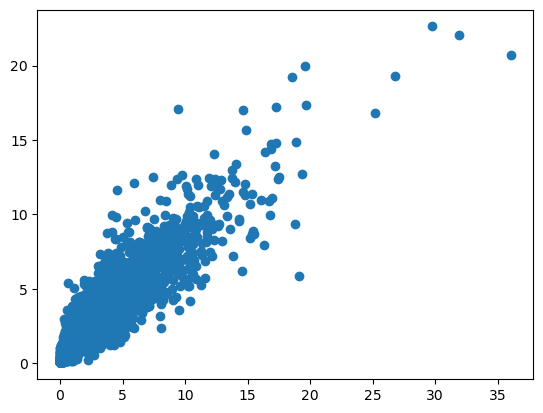

In [18]:
rf.fit(X_train, y_train)
# Make predictions
y_pred = rf.predict(X_test)
# Evaluate predictions
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
print('MAE: %.3f' % mae, 'r2: %.3f' % r2)

plt.scatter(y_test, y_pred) # 0.816

#### 4.c. Evaluate feature importance using individual features

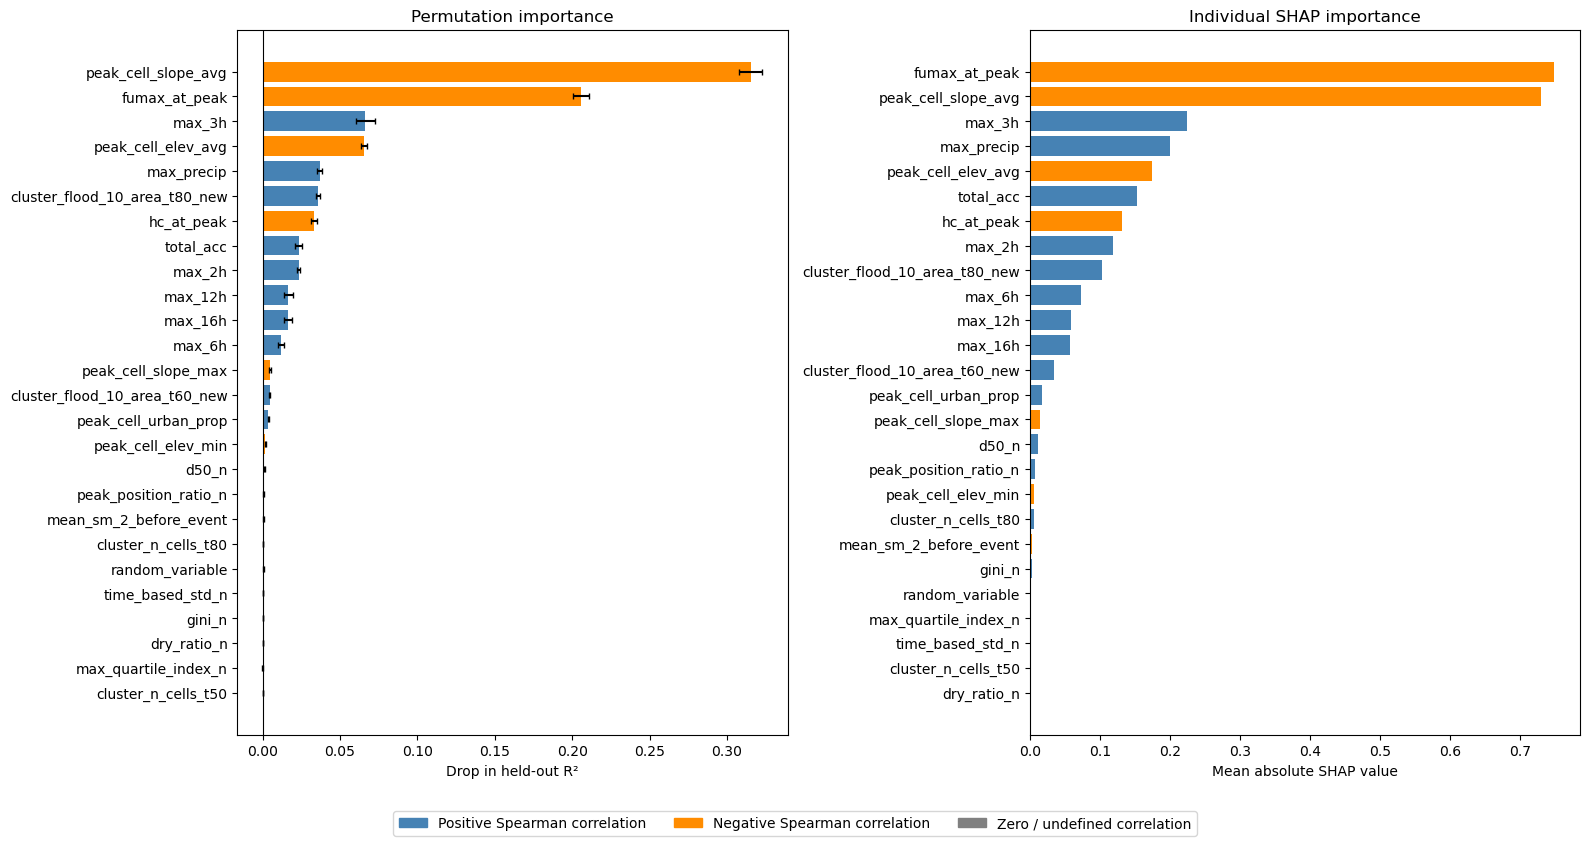

In [19]:
shap_results_individuals = shap_values_with_individual_predictors(X_test, rf, SEED, subset_size = None)    
pi_individual = permutation_importance_with_individual_predictors(X_test, y_test, rf, SEED)
predictor_corr_individual = find_correlations(subset_early, TARGET, predictor_variables, variable_groups)
plot_importance_scores(pi_individual,shap_results_individuals.summary, predictor_corr_individual )

#### 4.d. Evaluate feature importance using grouped features

In [20]:
def find_correlations(subset_early, TARGET, pi_df, grouped_variables):
    predictor_corr = {}
    for predictor in pi_df['predictor']:
        if predictor in grouped_variables:
            cols = [c for c in grouped_variables[predictor] if c in subset_early.columns]
            rhos = [spearmanr(subset_early[c], subset_early[TARGET], nan_policy="omit").statistic for c in cols]
            rho = np.nanmean(rhos) if rhos else np.nan
        else:  # Individual predictor
            if predictor in subset_early.columns:
                rho = spearmanr(subset_early[predictor], subset_early[TARGET], nan_policy="omit").statistic
            else:
                rho = np.nan
        predictor_corr[predictor] = rho
        
    return predictor_corr

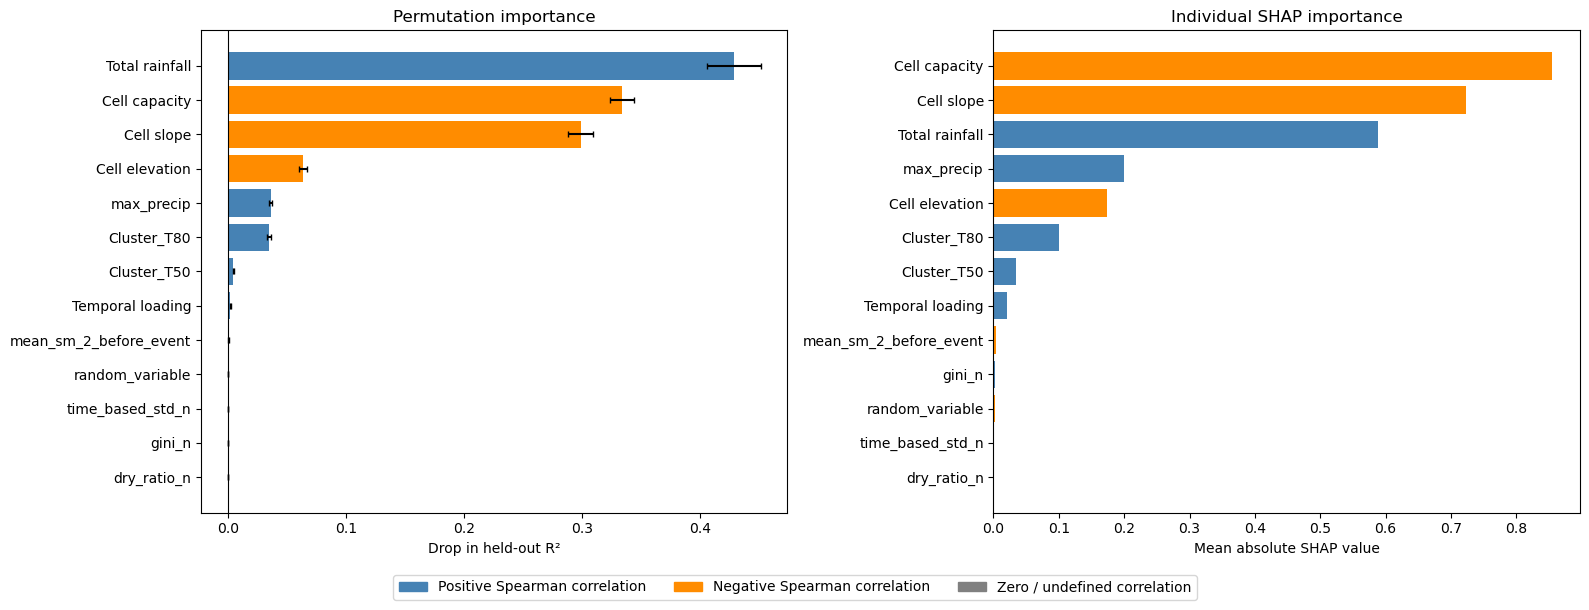

In [21]:
shap_results_groups = SHAP_values_with_groups(rf, X_test, individual_variables, variable_groups, SEED, subset_size = None)    
pi_groups = permutation_importance_with_groups(X_test, y_test, individual_variables,variable_groups,rf, SEED, n_repeats = 100)
# predictor_corr_groups = find_correlations(subset_early, TARGET, predictor_variables, variable_groups)
predictor_corr_groups = find_correlations(subset_early, TARGET, pi_groups, variable_groups)
plot_importance_scores(pi_groups, shap_results_groups.summary, predictor_corr_groups )

#### 4.e. Evaluate feature importance using SHAP specific plots 

#### SHAP specific plots: Beeswarm plots

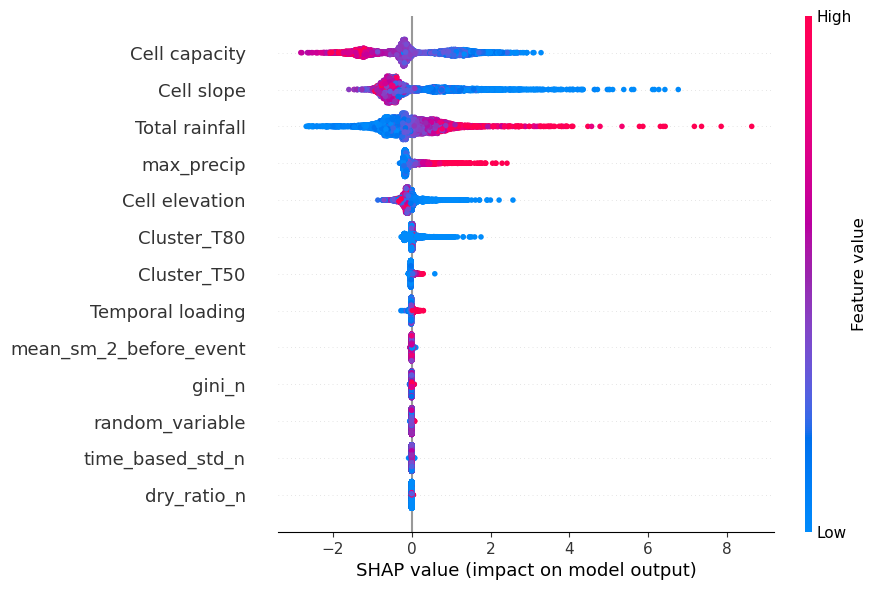

In [22]:
expl_all = make_grouped_explanation(shap_results_groups, variable_groups, individual_variables)
shap.plots.beeswarm(expl_all, max_display=20)

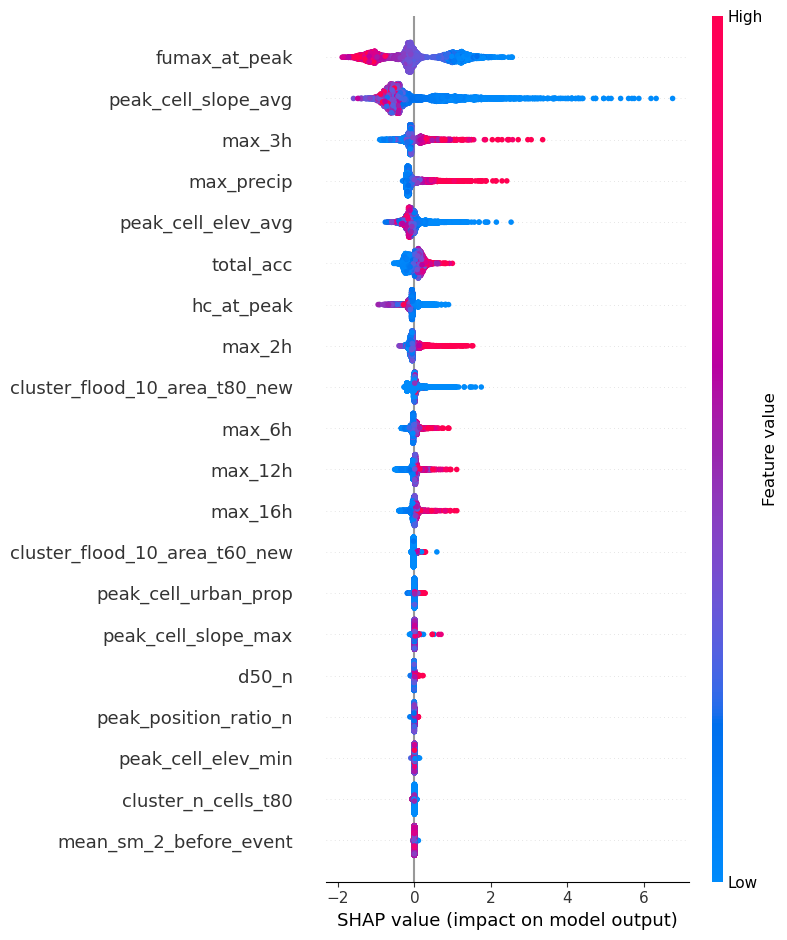

In [23]:
shap.summary_plot(shap_results_individuals.shap_values, shap_results_individuals.X_shap, show=True, max_display=20)

#### Other SHAP specific plots

Here we use SHAP functionalities to explore why some pixels get much less flooding than we'd expect them to

Waterfall plots:
- Waterfall plots are designed to display explanations for individual predictions. 
- The bottom of a waterfall plot starts as the expected value of the model output, and then each row shows how the positive (red) or negative (blue) contribution of each feature moves the value from the expected model output over the background dataset to the model output for this prediction.

Contrast values:
- Strongly negative: that driver pushes low pixels’ predictions down more than it does for rainfall-matched typical pixels. These are the candidate explanations for why those pixels respond so little.
- Near zero: the driver contributes about the same to both sets, so it doesn’t distinguish them.
- Positive: the driver pushes low pixels’ predictions up relative to typical pixels, i.e. it works against the low response (something else must be overpowering it).

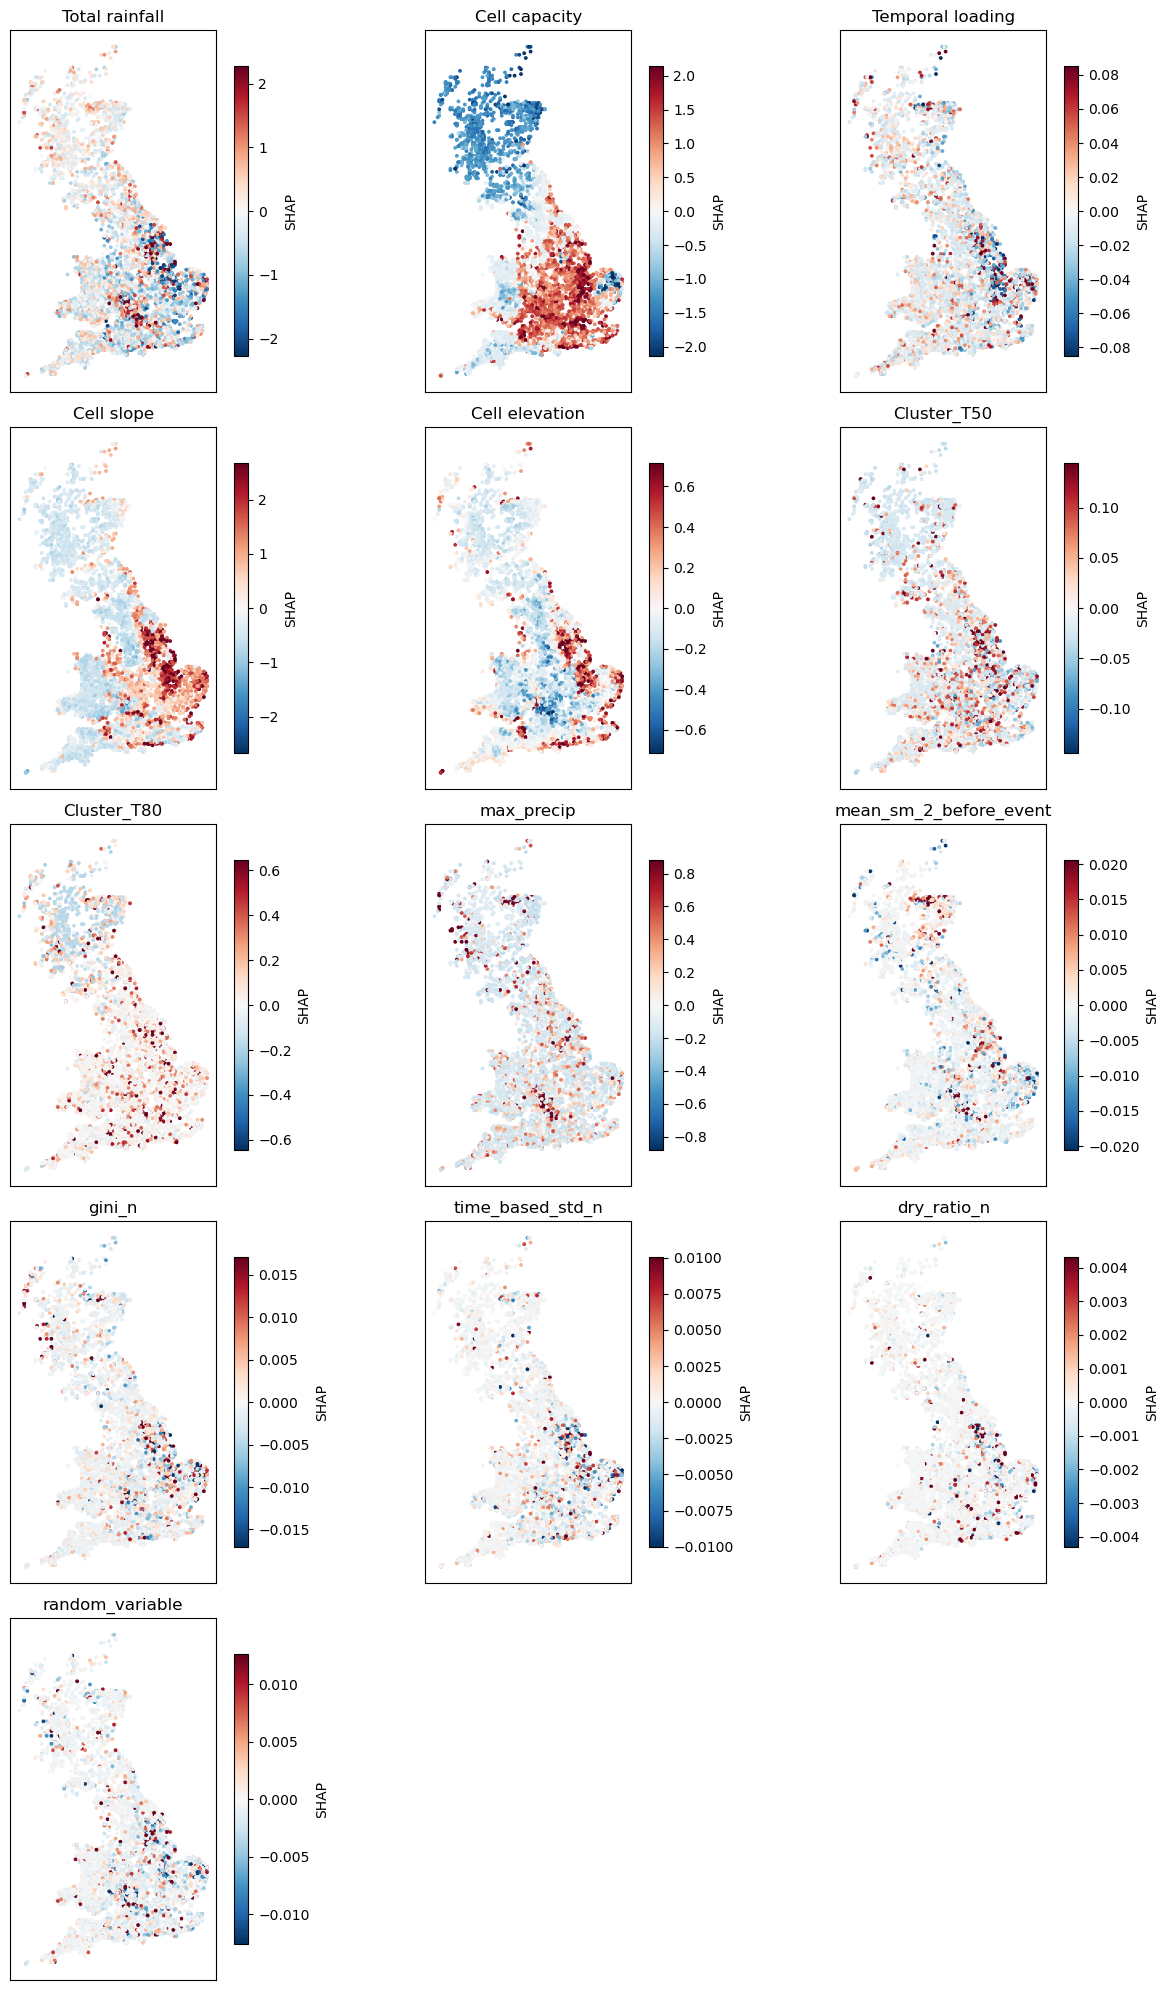

In [24]:
# Colour/data values for the waterfall: raw value for singletons, group summary for groups
grouped = pd.concat([shap_results_groups.group_shap_df, shap_results_groups.shap_df[individual_variables]], axis=1)

XCOL, YCOL = "x_coord", "y_coord"

# Coordinates for exactly the rows in `grouped`, in the same order
xy = subset_early.loc[grouped.index, [XCOL, YCOL]].to_numpy()

# All drivers, each with its own colour scale (shows the spatial pattern of every driver)
plot_shap_maps(grouped, xy)

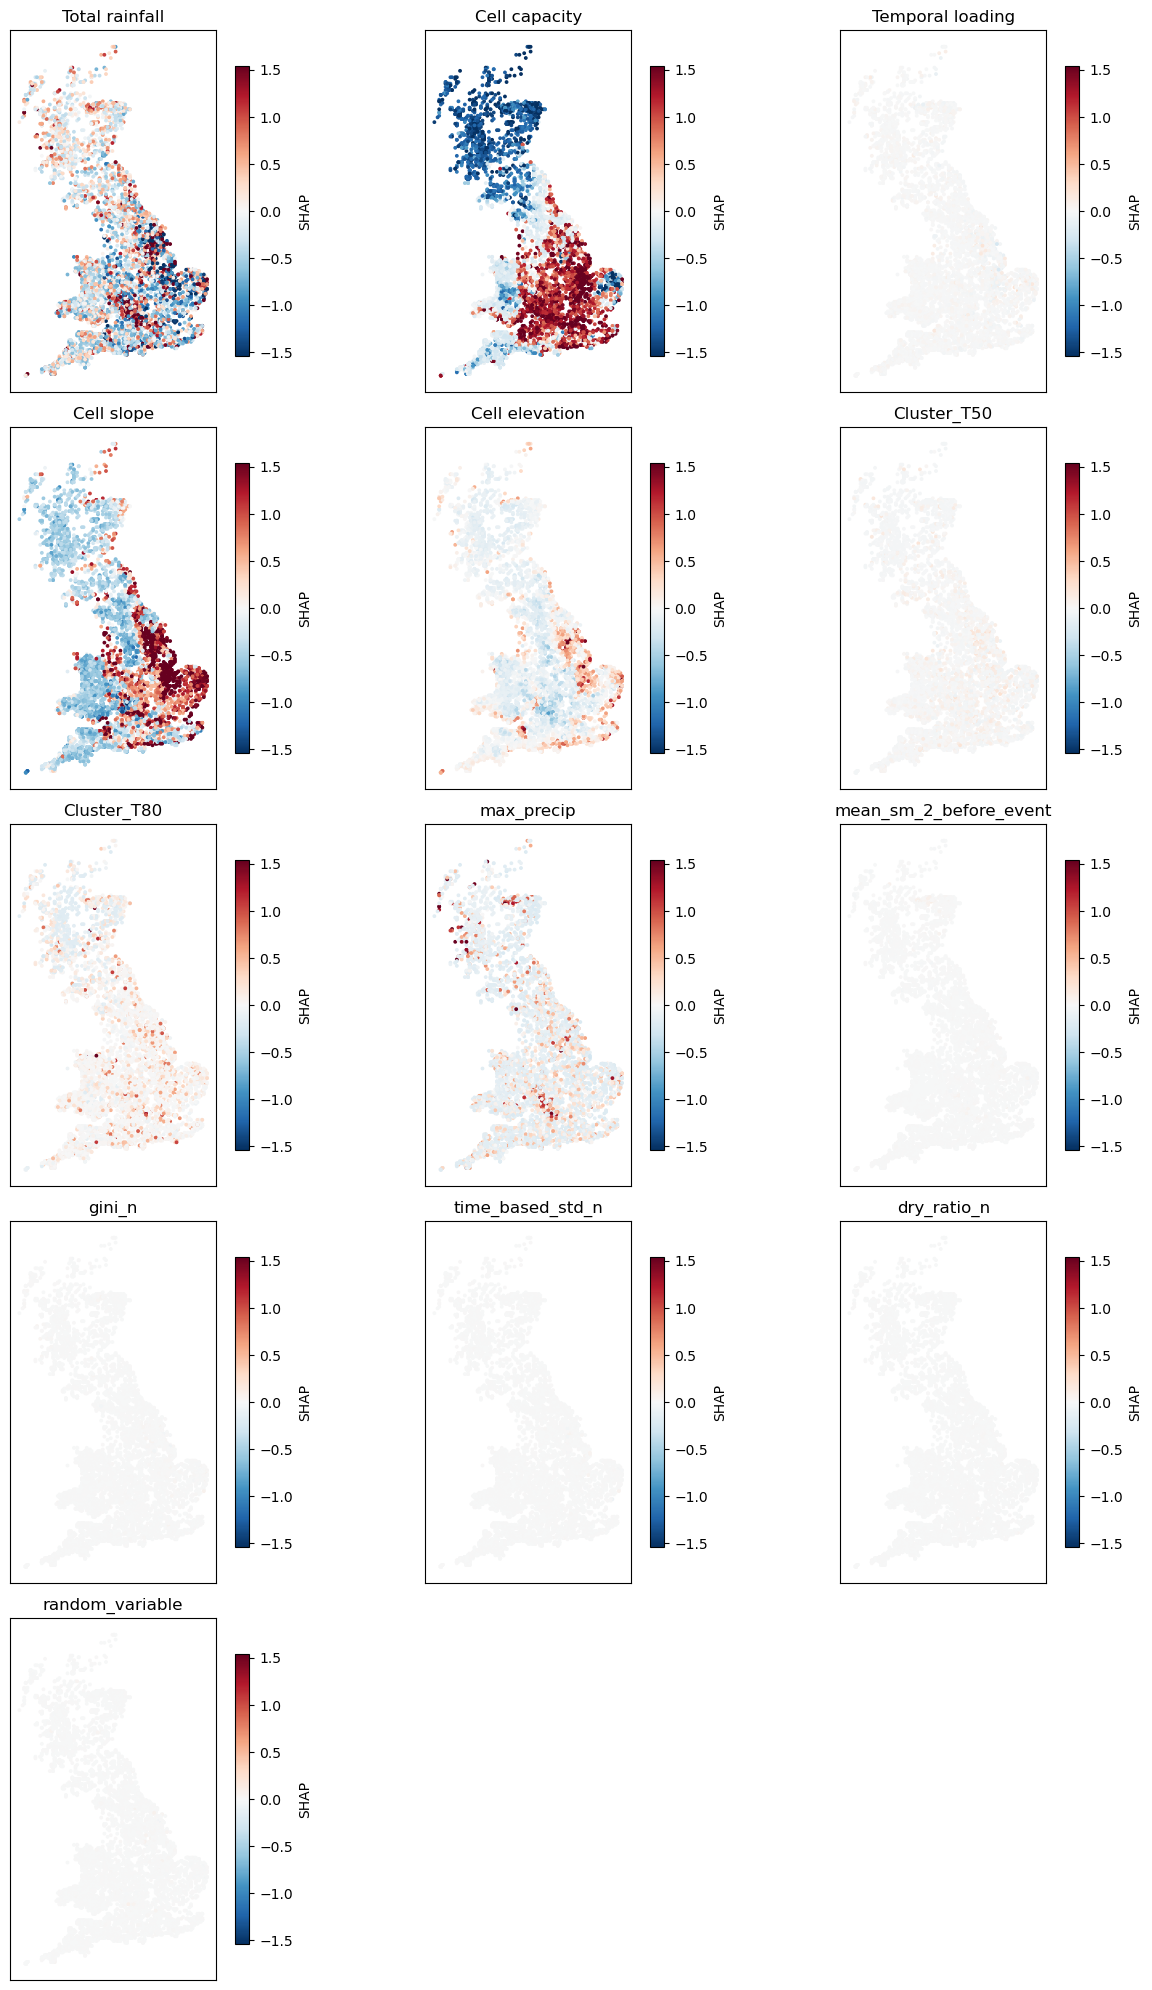

In [25]:
plot_shap_maps(grouped, xy, shared_scale=True)

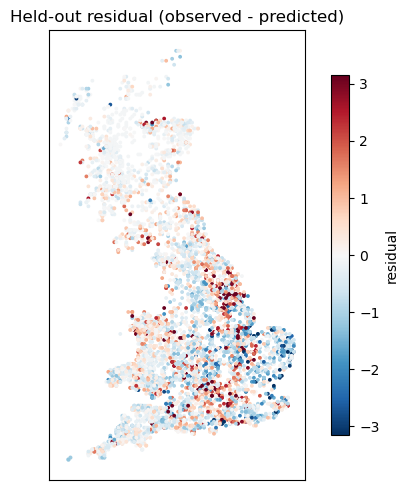

In [26]:
ys = pd.Series(np.asarray(y_test), index=X_test.index).loc[grouped.index]

resid = (ys - y_pred).loc[grouped.index]        # or (y - oof).loc[grouped.index]

lim = np.nanpercentile(np.abs(resid), 98)
fig, ax = plt.subplots(figsize=(5.5, 5))
sc = ax.scatter(xy[:, 0], xy[:, 1], c=resid.to_numpy(), s=3,
                cmap="RdBu_r", vmin=-lim, vmax=lim)
ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
ax.set_title("Held-out residual (observed - predicted)")
plt.colorbar(sc, ax=ax, shrink=0.8, label="residual")
plt.tight_layout(); plt.show()

### The single most influential driver per pixel:

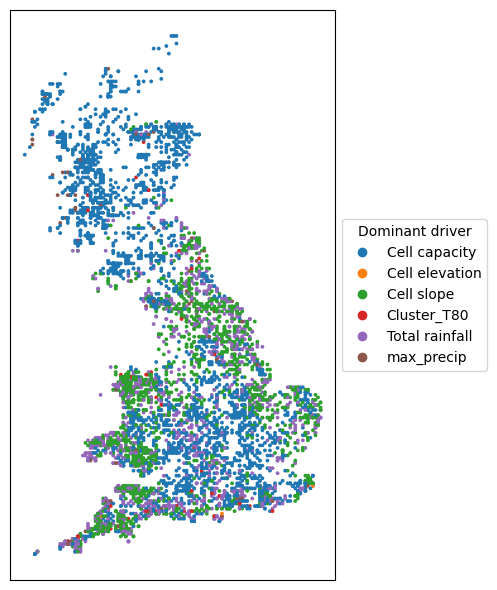

In [27]:
dominant = grouped.abs().idxmax(axis=1)
codes = dominant.astype("category")
cats = codes.cat.categories
n = len(cats)

cmap = plt.get_cmap("tab10" if n <= 10 else "tab20")
palette = [cmap(i) for i in range(n)]            # integer index -> the i-th colour exactly
point_colours = np.array(palette)[codes.cat.codes.to_numpy()]

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(xy[:, 0], xy[:, 1], c=point_colours, s=3)
ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])

handles = [plt.Line2D([], [], marker="o", ls="", color=palette[i], label=c)
           for i, c in enumerate(cats)]
ax.legend(handles=handles, title="Dominant driver",
          loc="center left", bbox_to_anchor=(1, 0.5))
plt.tight_layout(); plt.show()

### Interaction plot

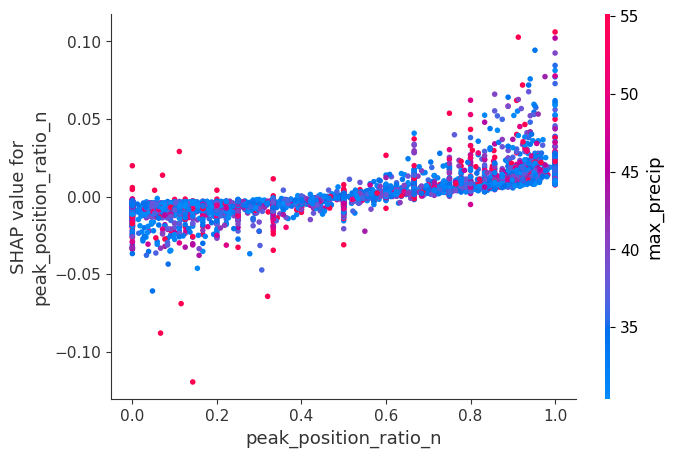

In [28]:
Xs = X.loc[grouped.index]
shap.dependence_plot("peak_position_ratio_n", shap_results_individuals.shap_df.values, Xs, interaction_index="max_precip")

------------------------------------
### EXPANSION: More complicated approaches for evaluating performance

1. Manual application of cross-validation:
    - This allows for construction of SHAP values and Permutation Importance within each fold
    - IT IS VERY SLOW!!

------------------------------------

In [29]:
cv_parameters = KFold(n_splits=5, shuffle=True, random_state=SEED)

list_shap_values, list_test_sets = [], []
fold_metrics, pi_records = [], []
pi_group_records = []        

for fold, (train_index, test_index) in enumerate(cv_parameters.split(X)):
    X_train, X_test = X.iloc[train_index], X.iloc[test_index]
    y_train, y_test = y.iloc[train_index], y.iloc[test_index]

    # --- fit ---
    t0 = time.perf_counter()
    clf = clone(rf).fit(X_train, y_train)
    t1 = time.perf_counter()

    # --- performance ---
    yhat = clf.predict(X_test)
    fold_metrics.append({"fold": fold,"r2": r2_score(y_test, yhat), "rmse": np.sqrt(mean_squared_error(y_test, yhat)),})

    # --- permutation importance ---
    t2 = time.perf_counter()
    pi = permutation_importance(clf, X_test, y_test, scoring="r2",
                                n_repeats=10, random_state=SEED, n_jobs=-1)
    pi_records.append(pd.DataFrame({"fold": fold, "predictor": X.columns, "PI_mean": pi.importances_mean, 
                                    "PI_sd": pi.importances_std,}))
    t3 = time.perf_counter()

    # --- SHAP ---
    sv = shap.TreeExplainer(clf).shap_values(X_test)
    list_shap_values.append(sv)
    list_test_sets.append(test_index)
    t4 = time.perf_counter()

    # ... inside the fold loop, after the SHAP step:
    pg = permutation_importance_with_groups(
        X_test, y_test, individual_variables, variable_groups,
        clf, SEED + fold, n_repeats=20)
    pg["fold"] = fold
    pi_group_records.append(pg)    

    print(f"fold {fold}: fit {t1-t0:.1f}s | PI {t3-t2:.1f}s | SHAP {t4-t3:.1f}s")


fold 0: fit 30.1s | PI 6.0s | SHAP 37.9s
fold 1: fit 30.0s | PI 2.2s | SHAP 38.2s
fold 2: fit 29.5s | PI 1.9s | SHAP 37.6s
fold 3: fit 29.6s | PI 2.3s | SHAP 37.8s
fold 4: fit 29.8s | PI 2.1s | SHAP 38.4s


In [30]:
# ---------- summaries ----------
metrics_df = pd.DataFrame(fold_metrics)
print(f"Full model R²: {metrics_df['r2'].mean():.4f} ± {metrics_df['r2'].std():.4f}")
print(f"Full model RMSE: {metrics_df['rmse'].mean():.4f}")

pi_all = pd.concat(pi_records, ignore_index=True)
pi_df = (pi_all.groupby("predictor")["PI_mean"]
               .agg(PI_mean="mean", PI_sd_across_folds="std")
               .sort_values("PI_mean", ascending=False))
pi_df.reset_index(inplace=True)
pi_df.rename(columns={'PI_sd_across_folds':'PI_sd'}, inplace=True)

pi_groups_all = pd.concat(pi_group_records, ignore_index=True)
pi_groups = (pi_groups_all.groupby("predictor")["PI_mean"].agg(PI_mean="mean", PI_sd="std")
             .sort_values("PI_mean", ascending=False).reset_index())

# SHAP reassembly as before
test_set = np.concatenate(list_test_sets)
shap_values_all = np.concatenate(list_shap_values, axis=0)
X_test_all = X.iloc[test_set]

shap_df = pd.DataFrame(shap_values_all, columns=X.columns, index=X.index[test_set])
shap_df = shap_df.loc[X.index]     
shap_df_summary = pd.DataFrame({"predictor": X.columns,
    "SHAP_mean_abs": shap_df.abs().mean().values}).sort_values("SHAP_mean_abs", ascending=False)

summary, group_shap_df = summarise_grouped_shap(shap_df, individual_variables, variable_groups)
shap_results_groups = ShapGroupResult(summary, shap_df, group_shap_df, X)

Full model R²: 0.8228 ± 0.0069
Full model RMSE: 1.0885


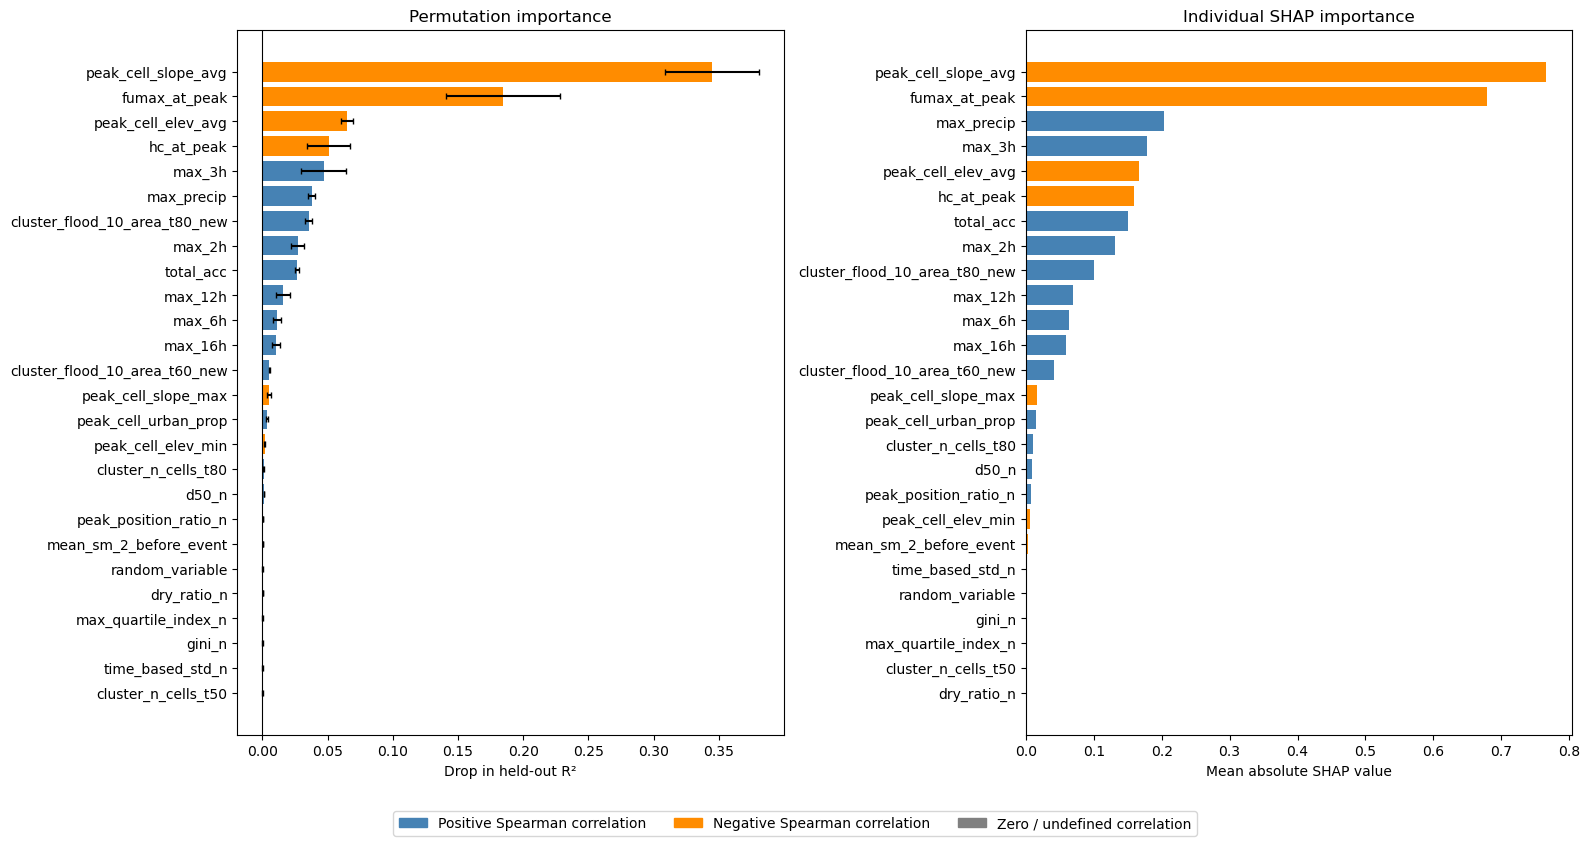

In [31]:
plot_importance_scores(pi_df, shap_df_summary, predictor_corr_individual )

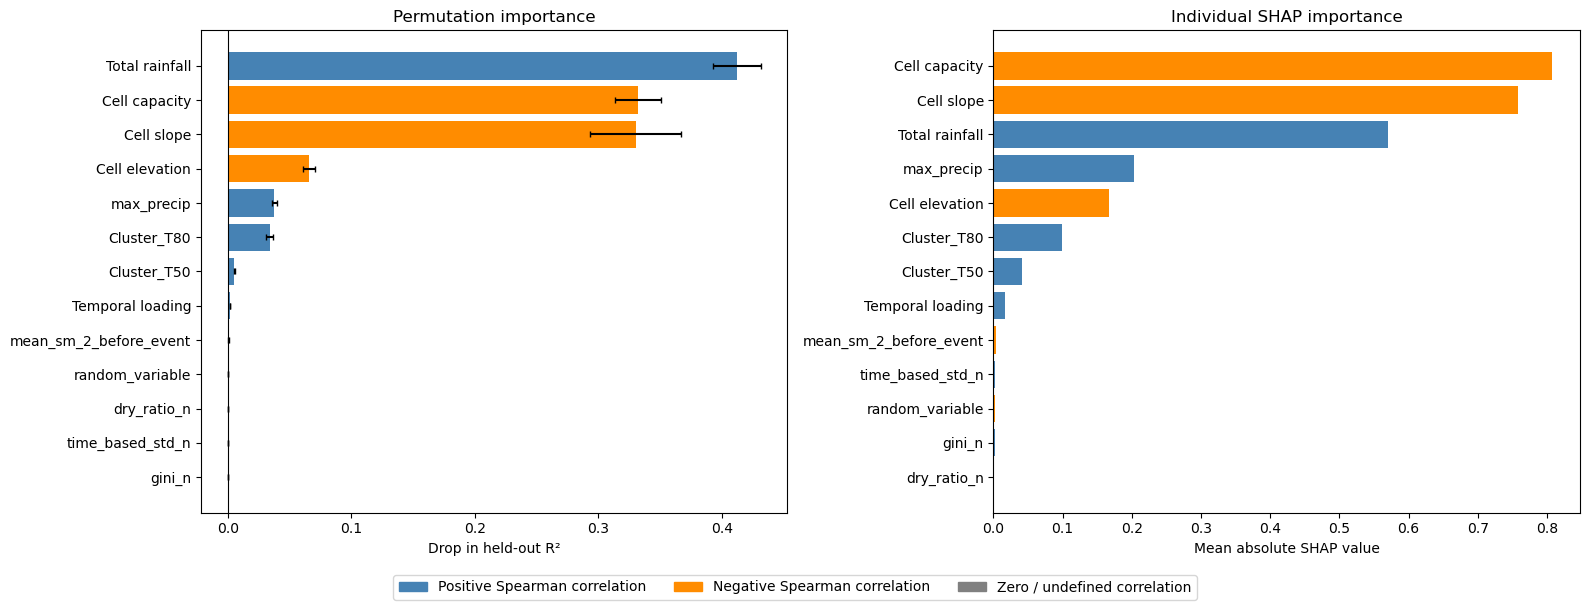

In [32]:
plot_importance_scores(pi_groups, shap_results_groups.summary, predictor_corr_groups )

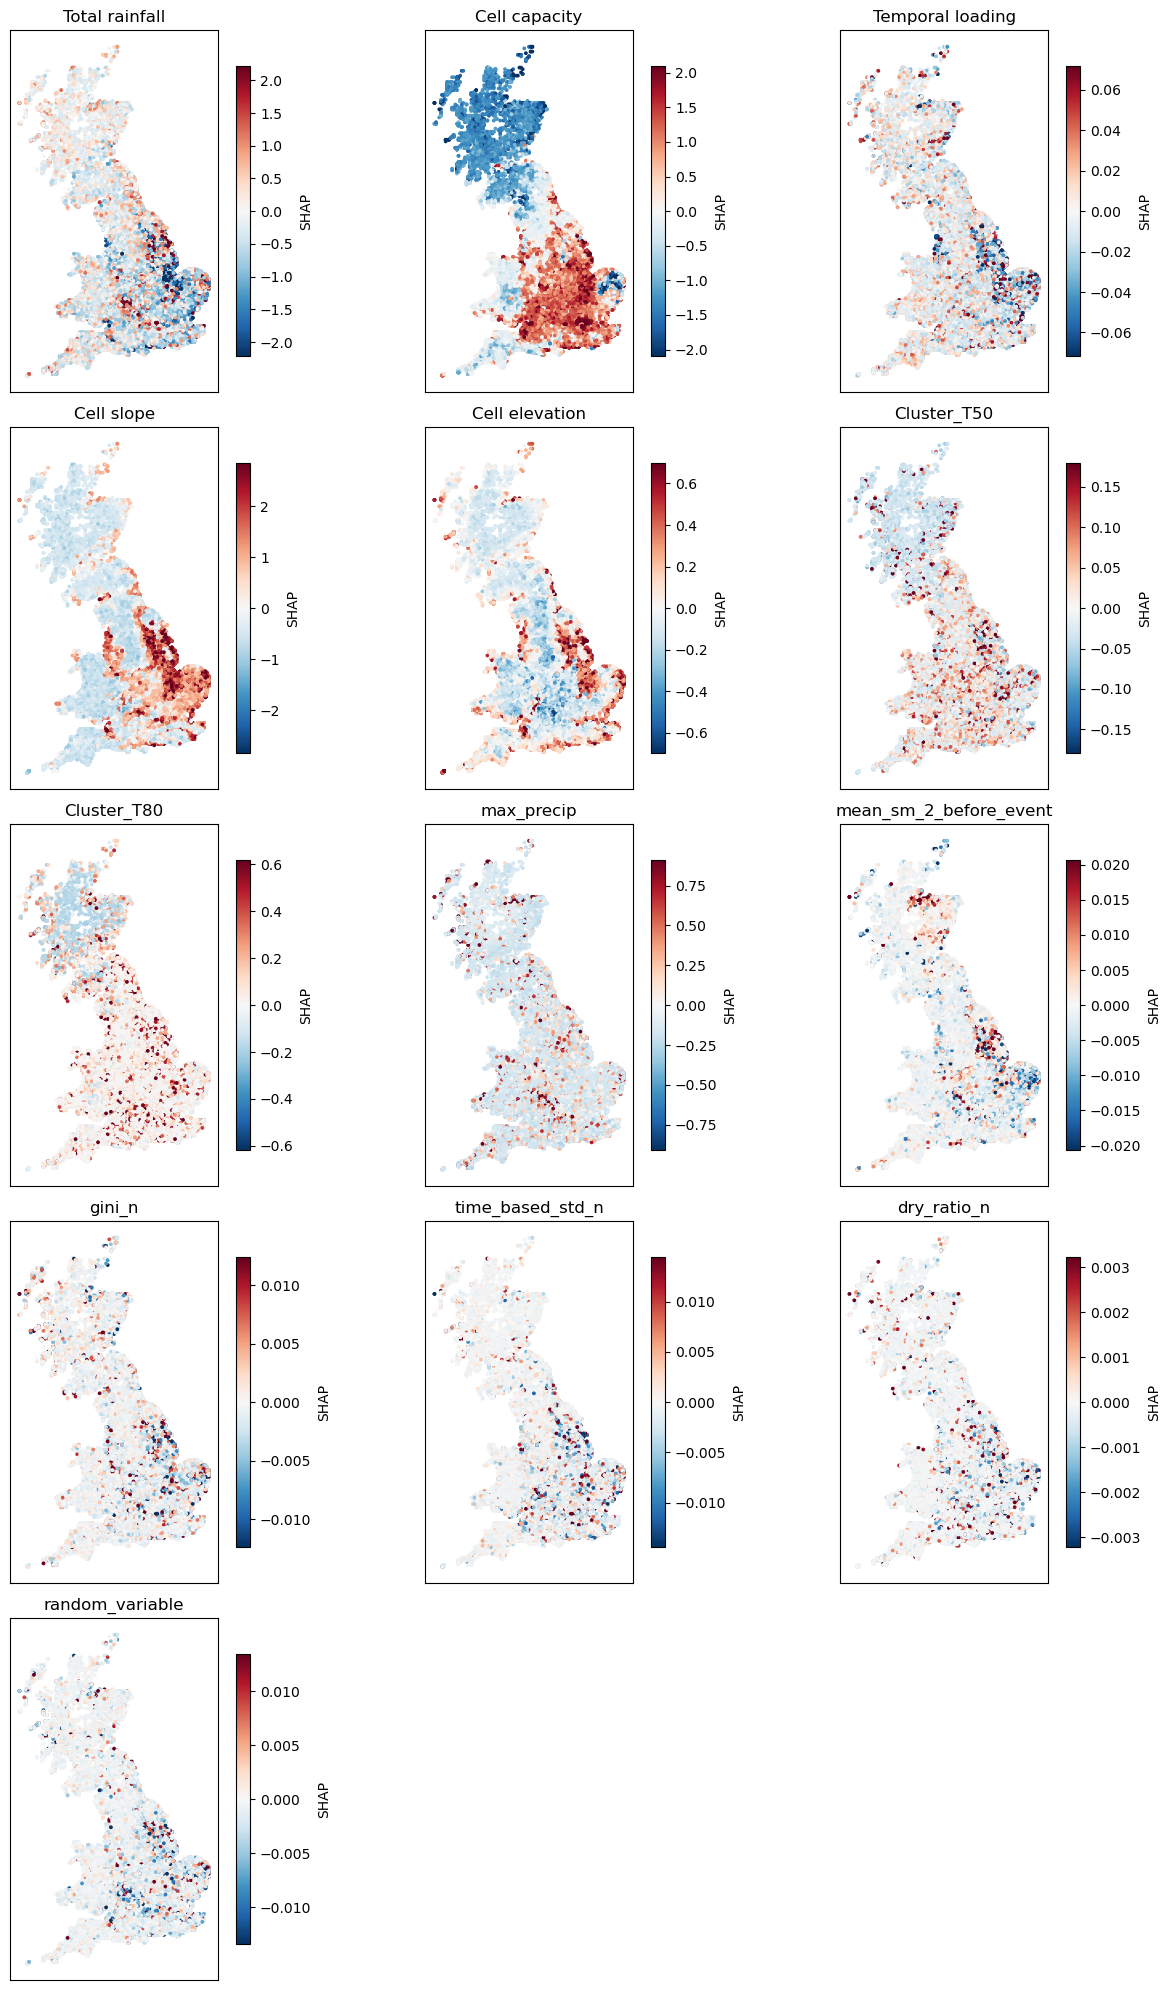

In [33]:
# Colour/data values for the waterfall: raw value for singletons, group summary for groups
grouped = pd.concat([shap_results_groups.group_shap_df, shap_results_groups.shap_df[individual_variables]], axis=1)

XCOL, YCOL = "x_coord", "y_coord"

# Coordinates for exactly the rows in `grouped`, in the same order
xy = subset_early.loc[grouped.index, [XCOL, YCOL]].to_numpy()

# All drivers, each with its own colour scale (shows the spatial pattern of every driver)
plot_shap_maps(grouped, xy)

In [34]:
# from sklearn.inspection import PartialDependenceDisplay
# PartialDependenceDisplay.from_estimator(
# rf, X,
#     features=['hc_at_peak',
#               ('hc_at_peak', 'max_precip')],  # 2D interaction plot
#     kind='average')

------------------------------------
### EXPANSION: More complicated approaches for evaluating performance

2. Most complex application
    - Involves repeating the kfold CV process.  
    - Doesn't currently calculate the evaluation metrics or permutation importance.  
    - Decided it is probably overkill as even crazier SLOW

Based on : https://medium.com/data-science/using-shap-with-cross-validation-d24af548fadc

------------------------------------

In [35]:
# for i, CV_repeat in enumerate(range(CV_repeats)): #-#-#
#     #Verbose 
#     print('\n------------ CV Repeat number:', CV_repeat)
#     #Establish CV scheme
#     CV = KFold(n_splits=5, shuffle=True, random_state=random_states[i]) # Set random state 

#     ix_training, ix_test = [], []
#     # Loop through each fold and append the training & test indices to the empty lists above
#     for fold in CV.split(X):
#         ix_training.append(fold[0]), ix_test.append(fold[1])
        
#     ## Loop through each outer fold and extract SHAP values 
#     for i, (train_outer_ix, test_outer_ix) in enumerate(zip(ix_training, ix_test)): 
#         #Verbose
#         print('\n------ Fold Number:',i)
#         X_train, X_test = X.iloc[train_outer_ix, :], X.iloc[test_outer_ix, :]
#         y_train, y_test = y.iloc[train_outer_ix], y.iloc[test_outer_ix]
        
#         model = RandomForestRegressor(random_state=10) # Random state for reproducibility (same results every time)
#         fit = model.fit(X_train, y_train)
#         yhat = fit.predict(X_test)
#         result = mean_squared_error(y_test, yhat)
#         print('RMSE:',round(np.sqrt(result),4))

#         # Use SHAP to explain predictions
#         explainer = shap.TreeExplainer(model)
#         shap_values = explainer.shap_values(X_test)

#         # Extract SHAP information per fold per sample 
#         for i, test_index in enumerate(test_outer_ix):
#             shap_values_per_cv[test_index][CV_repeat] = shap_values[i] #-#-#